In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [4]:
df=pd.read_csv("../data/raw/train.csv")
df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
print("Rows and Columns:",df.shape)
df.columns
df.info()


Rows and Columns: (614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
df['Gender'].fillna(df["Gender"].mode()[0],inplace=True)
df["Married"].fillna(df['Married'].mode()[0],inplace=True)
df['Dependents'].fillna(df['Dependents'].mode()[0],inplace=True)
df['Self_Employed'].fillna(df['Self_Employed'].mode()[0],inplace=True)

In [8]:
df["LoanAmount"].fillna(df["LoanAmount"].median(),inplace=True)
df["Loan_Amount_Term"].fillna(df['Loan_Amount_Term'].median(),inplace=True)
df['Credit_History'].fillna(df["Credit_History"].median(),inplace=True)

In [9]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [56]:
df.to_csv("../data/processed/cleaned_data.csv", index=False)

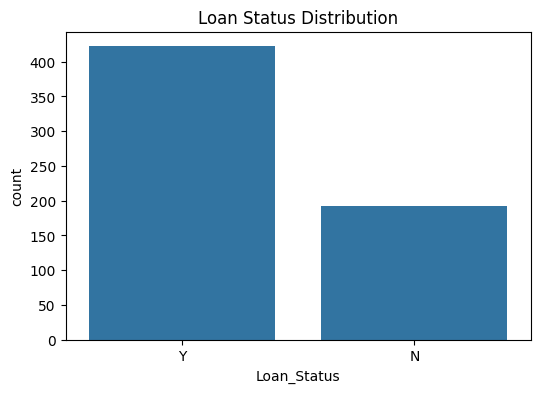

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x='Loan_Status',data=df)
plt.title("Loan Status Distribution")
plt.show()

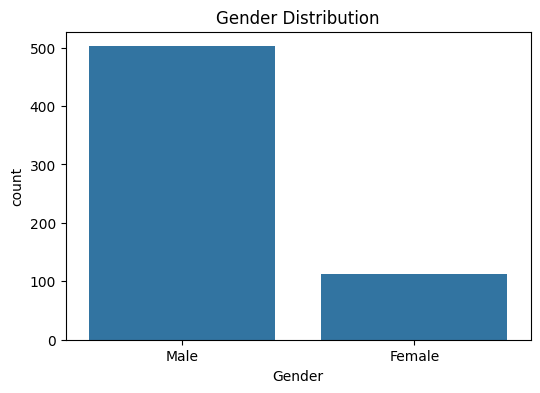

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(x='Gender',data=df)
plt.title("Gender Distribution")
plt.show()

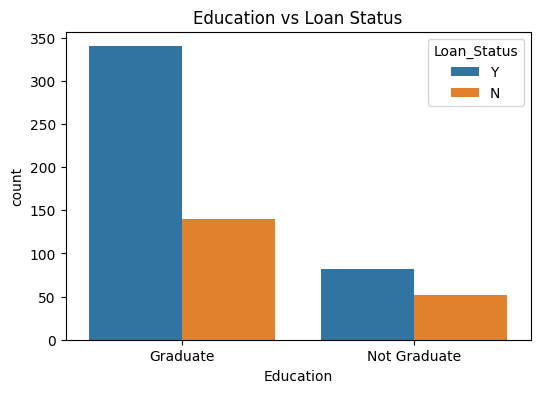

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x="Education",hue="Loan_Status",data=df)
plt.title("Education vs Loan Status")
plt.show()

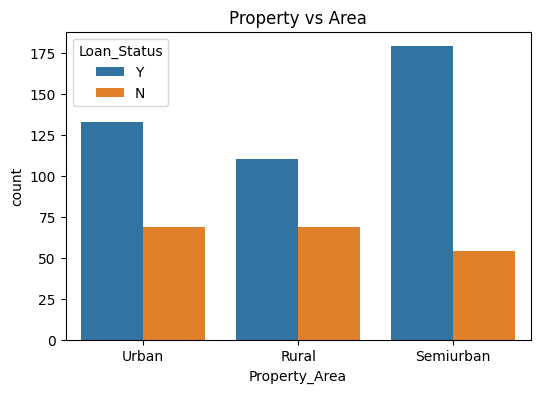

In [13]:
plt.figure(figsize=(6,4))
sns.countplot(x='Property_Area',hue='Loan_Status',data=df)
plt.title("Property vs Area")
plt.show()

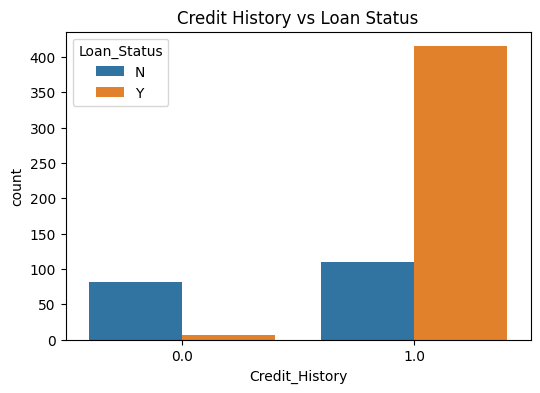

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x="Credit_History",hue="Loan_Status",data=df)
plt.title("Credit History vs Loan Status")
plt.show()

In [15]:
df.drop("Loan_ID",axis=1,inplace=True)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [16]:
X=df.drop('Loan_Status',axis=1)
y=df["Loan_Status"]

In [17]:
y=y.map({"Y":1,"N":0})
y.head()

0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64

In [18]:
X=pd.get_dummies(X,drop_first=True)
X.head()


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,True,False,False,False,False,False,False,False,True
1,4583,1508.0,128.0,360.0,1.0,True,True,True,False,False,False,False,False,False
2,3000,0.0,66.0,360.0,1.0,True,True,False,False,False,False,True,False,True
3,2583,2358.0,120.0,360.0,1.0,True,True,False,False,False,True,False,False,True
4,6000,0.0,141.0,360.0,1.0,True,False,False,False,False,False,False,False,True


In [19]:
print("Shape after Encoding:",X.shape)

Shape after Encoding: (614, 14)


In [57]:
processed_df = X.copy()
processed_df["Loan_Status"] = y
processed_df.to_csv("../data/processed/final_processed_data.csv", index=False)

In [20]:
from imblearn.over_sampling import SMOTE
print(y.value_counts())

Loan_Status
1    422
0    192
Name: count, dtype: int64


In [21]:
smote=SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

In [22]:
print(y_resampled.value_counts())

Loan_Status
1    422
0    422
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled,
    y_resampled,
    test_size=0.2,
    random_state=42
)

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import joblib

In [27]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [28]:
print("===== Logistic Regression =====")
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1 Score :", f1_score(y_test, lr_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lr_pred))

===== Logistic Regression =====
Accuracy : 0.7337278106508875
Precision: 0.6442307692307693
Recall   : 0.8933333333333333
F1 Score : 0.7486033519553073
ROC-AUC  : 0.7498581560283689


In [29]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

In [30]:
print("===== Decision Tree =====")
print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))
print("ROC-AUC  :", roc_auc_score(y_test, dt_pred))

===== Decision Tree =====
Accuracy : 0.7633136094674556
Precision: 0.7464788732394366
Recall   : 0.7066666666666667
F1 Score : 0.726027397260274
ROC-AUC  : 0.7575886524822695


In [31]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [32]:
print("===== Random Forest =====")
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_pred))

===== Random Forest =====
Accuracy : 0.8284023668639053
Precision: 0.7674418604651163
Recall   : 0.88
F1 Score : 0.8198757763975155
ROC-AUC  : 0.8336170212765958


In [34]:
joblib.dump(lr_model, "../models/logistic_regression_model.pkl")
joblib.dump(dt_model, "../models/decision_tree_model.pkl")
joblib.dump(rf_model, "../models/random_forest_model.pkl")
joblib.dump(X.columns.tolist(), "../models/model_columns.pkl")

['../models/model_columns.pkl']

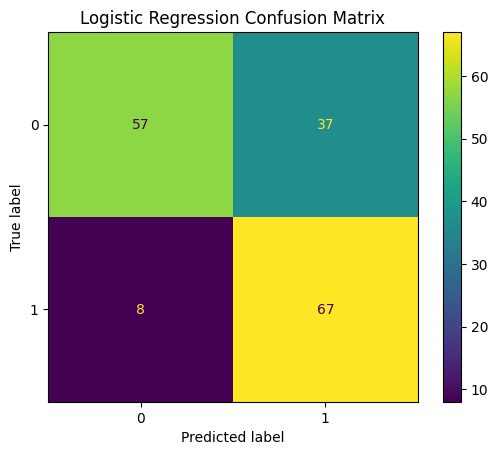

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

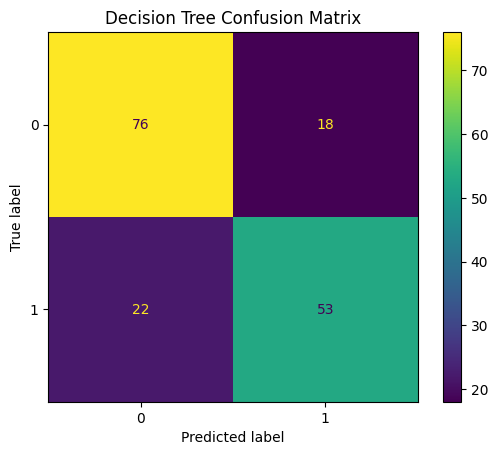

In [37]:
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred)
plt.title("Decision Tree Confusion Matrix")
plt.show()

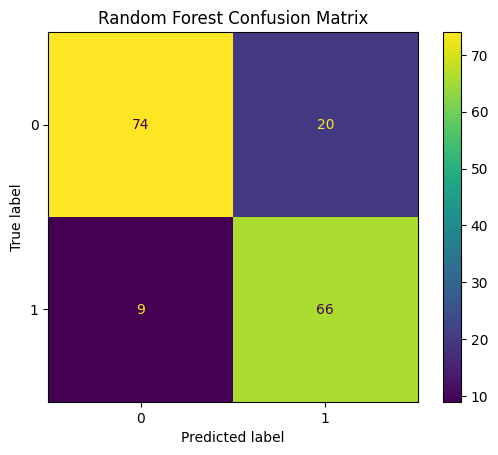

In [38]:
ConfusionMatrixDisplay.from_predictions(y_test,rf_pred)
plt.title("Random Forest Confusion Matrix")
plt.show()

In [39]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.88      0.61      0.72        94
           1       0.64      0.89      0.75        75

    accuracy                           0.73       169
   macro avg       0.76      0.75      0.73       169
weighted avg       0.77      0.73      0.73       169



In [40]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.78      0.81      0.79        94
           1       0.75      0.71      0.73        75

    accuracy                           0.76       169
   macro avg       0.76      0.76      0.76       169
weighted avg       0.76      0.76      0.76       169



In [41]:
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.89      0.79      0.84        94
           1       0.77      0.88      0.82        75

    accuracy                           0.83       169
   macro avg       0.83      0.83      0.83       169
weighted avg       0.84      0.83      0.83       169



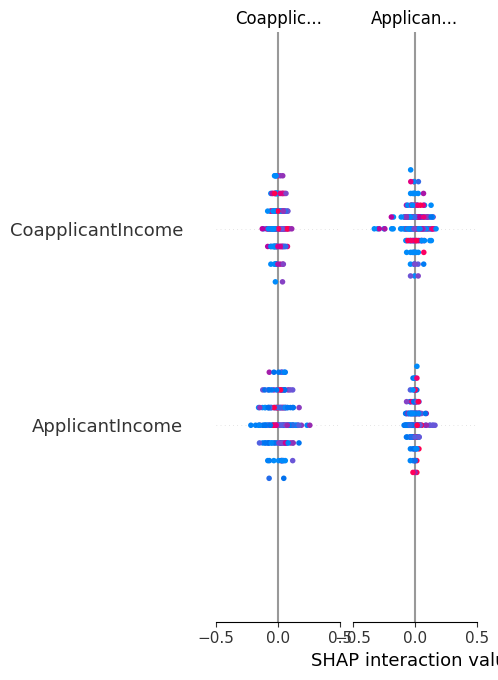

In [45]:
best_model = rf_model

import shap
explainer=shap.TreeExplainer(best_model)
shap_values=explainer.shap_values(X_test)
shap.summary_plot(shap_values,X_test)

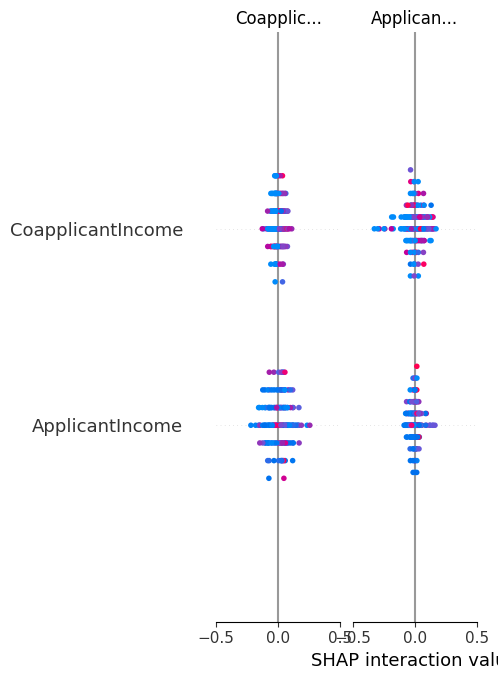

In [ ]:
shap.summary_plot(shap_values,X_test,plot_type="bar")

In [47]:
import joblib 
joblib.dump(best_model,"../models/credit_risk_model.pkl")
joblib.dump(X.columns.tolist(),"../models/model_columns.pkl")

['../models/model_columns.pkl']

In [48]:
from lime.lime_tabular import LimeTabularExplainer
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns,
    class_names=["Rejected","Approved"],
    mode="classification"
)

In [51]:
exp = explainer.explain_instance(
    X_test.iloc[0].values,
    best_model.predict_proba,
    num_features=10
)


In [52]:
exp.show_in_notebook(show_table=True)

In [54]:
exp.save_to_file("../reports/lime_explanation.html")